# Runtime and particle separation

Compare BM4Implicit (symmetric projection), two-stage Gauss–Legendre and explicit midpoint RK2 with NumPy/SciPy and JAX, using the union of sets 3 and 4 (16 particles) and normalized rho=0.015. Each method runs for 10, 30 and 90 cycles, with 40 fixed steps and ten saved samples per cycle plus the initial state. Each method-duration case has one first call and three later repetitions per library: nine cases, 12 executions per method and 36 executions per library.

Within each case, both libraries run sequentially in the same two-core Modal CPU container with float64, alternating their order. Timing includes preparation, integration, synchronization and result construction, and excludes container startup, input decoding, transfers and plotting. The first JAX call compiles; later calls reuse its executable.

Load and verify the saved archives, then draw two French-labelled figures for the thesis. This notebook does not integrate trajectories. It uses the local archives when available, or loads them from the same B2 prefix as `calcul.ipynb`.

Particle separation means the Euclidean distance between the positions of the **same particle** computed by the two libraries, in unwrapped base-cell coordinates. The two panels distinguish the eight chaotic candidates (12, 15, 18, 21, 24, 27, 30, 33) from the eight periodic candidates (1, 2, 60, 64, 65, 72, 76, 83). Membership is resolved from archived IDs and checked against the selected particles' physical positions; both classifications remain provisional.

In [1]:
from pathlib import Path
import json
import sys

# Locate the code repository from this section folder or its parent directories.
ROOT = next(
    (candidate.resolve()
     for parent in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     for candidate in (parent, parent / "GC2D_codigo")
     if (candidate / "src/studies/bm4_numpy_jax.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "GC2D_codigo was not found. Keep it beside TFM_redaccion "
        "or start the notebook from the code repository."
    )
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

STUDY_PREFIX = "studies/bm4_numpy_jax"
RUN_ID = "methods-20261119-union16-rho0015-c10-30-90"
RUN_DIRECTORY = ROOT / "outputs" / STUDY_PREFIX / RUN_ID
BUCKET = f"gc2d_data:gc2d-notebooks-data/{STUDY_PREFIX}/{RUN_ID}"

# Enable to archive this derived revision in the study bucket.
ARCHIVE_DERIVED = False


In [2]:
from visualization.bm4_numpy_jax import summarize, export_figure, export_agreement_figure

summary = summarize(RUN_DIRECTORY, bucket=BUCKET, particle_groups={
    "chaotic": ROOT / "data/particles/chaotic_candidates.json",
    "periodic": ROOT / "data/particles/periodic_candidates_8.json",
})
assert summary["study"]["particle_count"] == 16
assert summary["study"]["cycles"] == [10, 30, 90]
assert summary["study"]["methods"] == ["BM4Implicit", "GaussLegendre4", "RK2"]
for group, record in summary["particle_groups"].items():
    assert len(record["available_particle_ids"]) == 8 and not record["missing_particle_ids"]
    print(f"{group}: available IDs {record['available_particle_ids']}; missing IDs {record['missing_particle_ids']}")
for row in summary["rows"]:
    groups = row["group_distances"]
    print(f"{row['method']:14s} {row['cycles']:3d} cycles | speedup {row['speedup']:.2f} | "
          f"chaotic maximum {groups['chaotic']['maximum_distance']:.3e} | "
          f"periodic maximum {groups['periodic']['maximum_distance']:.3e}")

chaotic: available IDs [12, 15, 18, 21, 24, 27, 30, 33]; missing IDs []
periodic: available IDs [1, 2, 60, 64, 65, 72, 76, 83]; missing IDs []
BM4Implicit     10 cycles | speedup 16.31 | chaotic maximum 8.162e-14 | periodic maximum 8.731e-15
GaussLegendre4  10 cycles | speedup 30.80 | chaotic maximum 4.947e-14 | periodic maximum 7.791e-15
RK2             10 cycles | speedup 27.52 | chaotic maximum 2.706e-14 | periodic maximum 4.960e-15
BM4Implicit     30 cycles | speedup 20.84 | chaotic maximum 1.824e-12 | periodic maximum 3.818e-14
GaussLegendre4  30 cycles | speedup 39.45 | chaotic maximum 1.061e-12 | periodic maximum 6.488e-14
RK2             30 cycles | speedup 35.30 | chaotic maximum 1.181e-12 | periodic maximum 1.346e-14
BM4Implicit     90 cycles | speedup 17.18 | chaotic maximum 1.837e-06 | periodic maximum 2.997e-13
GaussLegendre4  90 cycles | speedup 35.78 | chaotic maximum 1.025e-06 | periodic maximum 5.347e-13
RK2             90 cycles | speedup 20.55 | chaotic maximum 7.554

## Runtime

Filled markers show the median of three warmed repetitions, bars their minimum–maximum interval, and hollow markers the first call. Method colors are shared across both figures; circles and solid lines identify NumPy/SciPy, squares and dashed lines identify JAX. Both axes are logarithmic. Export a vector PDF, a PNG and a JSON provenance record.

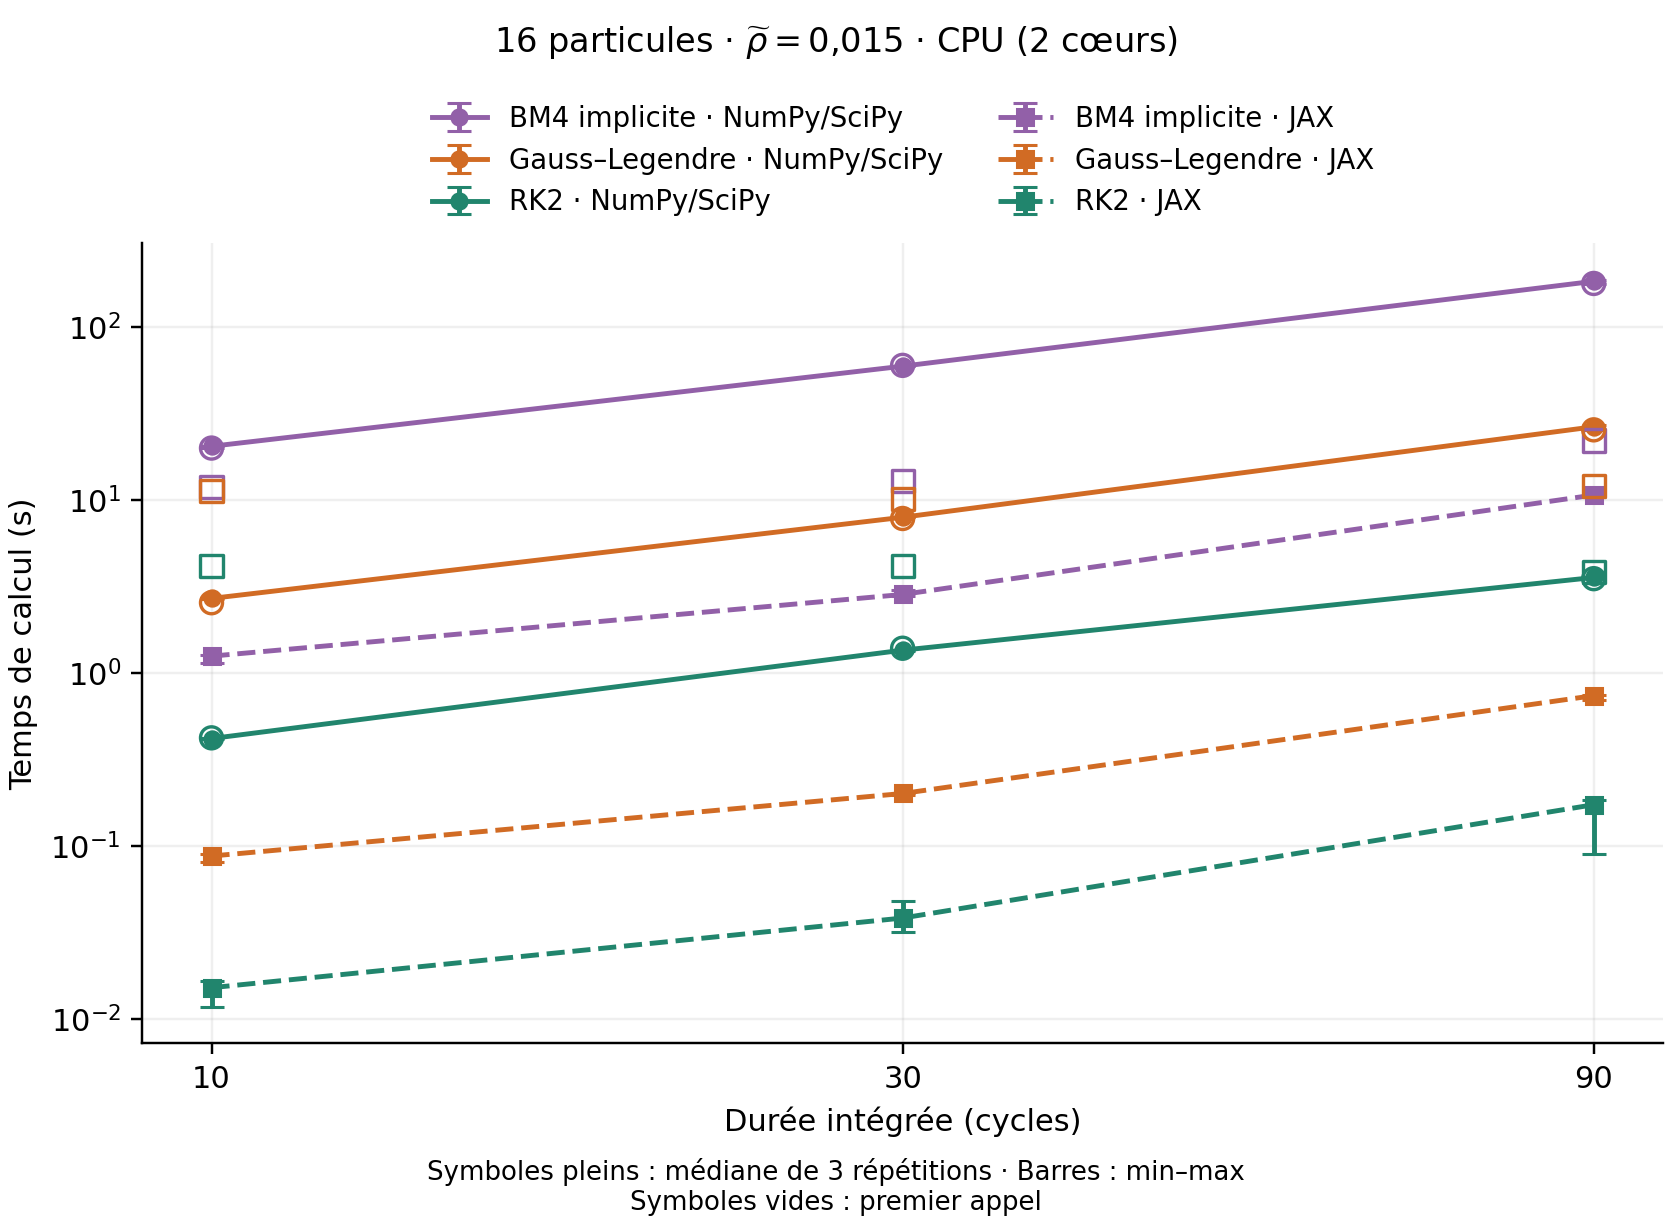

In [3]:
from IPython.display import Image, display
import matplotlib.pyplot as plt

FIGURE = ROOT.parent / "TFM_redaccion/figuras/comparacion_numpy_jax_fr"
figure = export_figure(summary, FIGURE)
plt.close(figure)
display(Image(filename=str(FIGURE.with_suffix(".png"))))


After compilation, JAX is faster in all nine cases: the ratio of NumPy/SciPy to JAX median runtime ranges from 16.3 to 39.4. Compilation can reverse the comparison for a short first call, as with RK2 at ten cycles. The gain therefore depends on executable reuse. The processor model was not recorded, so equal resource requests do not establish identical physical hardware across cases.

## Particle separation

Each point is the maximum Euclidean backend distance over the available particles in its group and **all saved times** in that case. Both panels use the same logarithmic scales. Each duration is an independent calculation; connecting lines are visual guides, not a time history of one trajectory. Zero values are never replaced by an artificial positive floor.

The exported JSON retains all-particle statistics, separate group statistics, available and missing IDs, selection fingerprints and the distance convention.

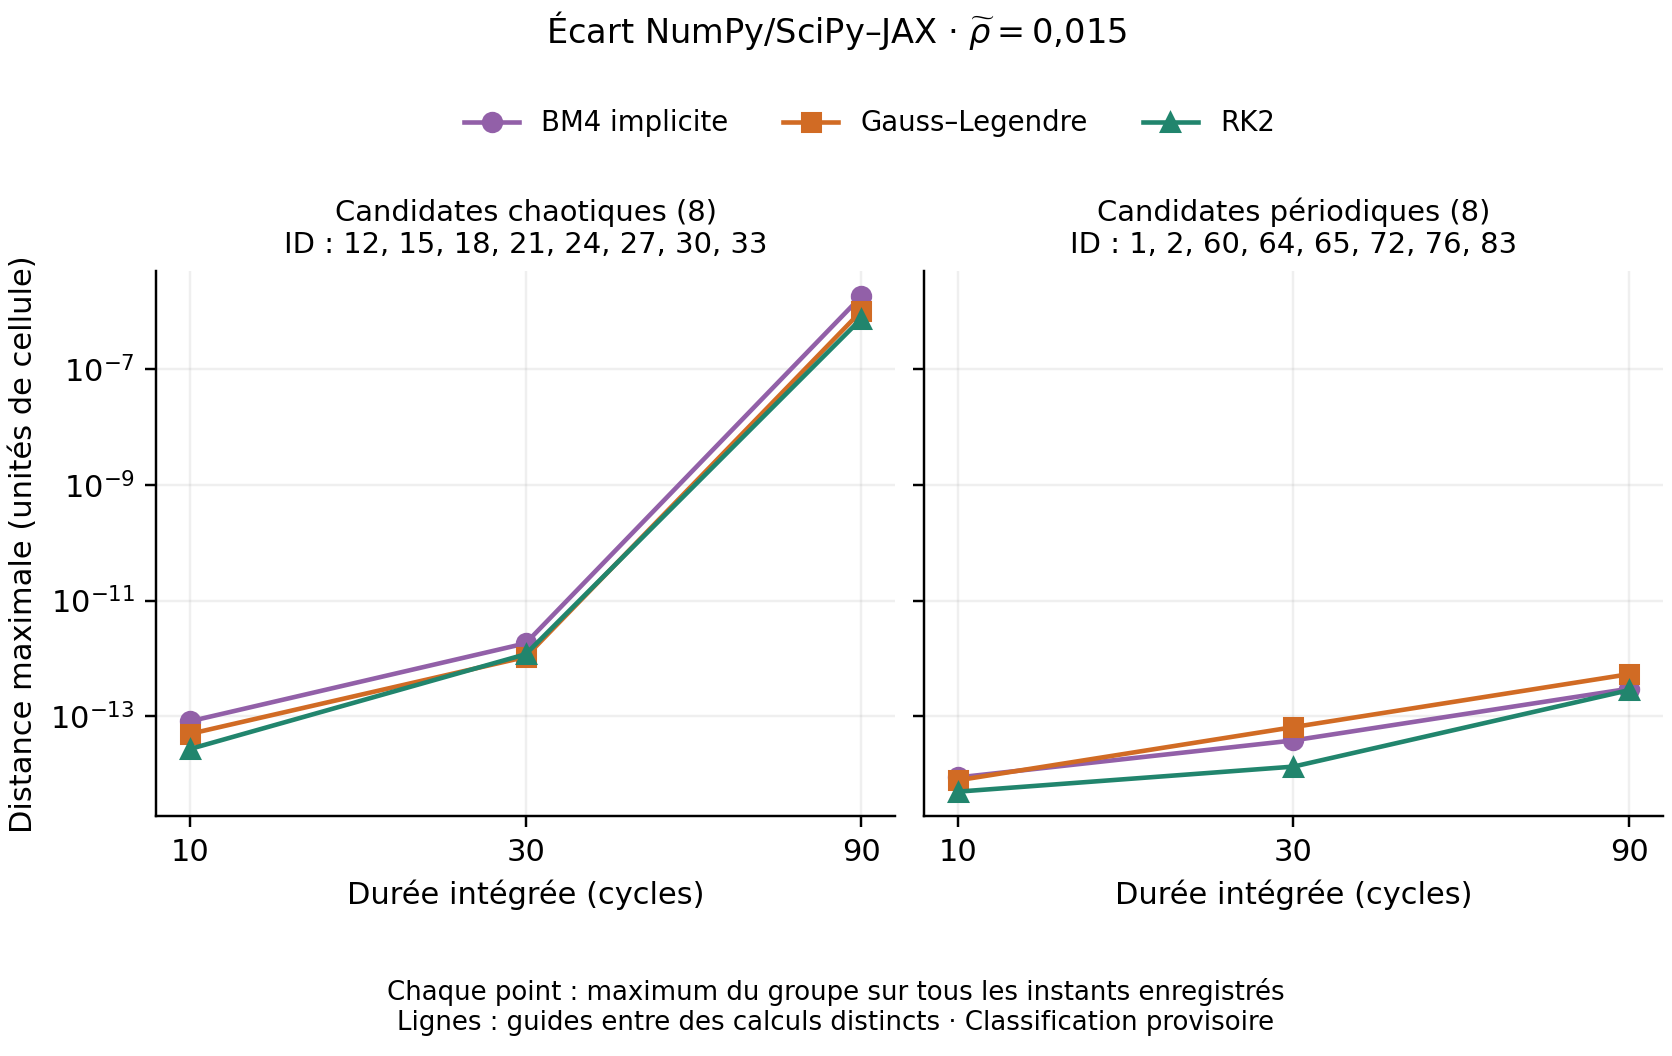

In [4]:
AGREEMENT_FIGURE = ROOT.parent / "TFM_redaccion/figuras/concordancia_numpy_jax_fr"
agreement_figure = export_agreement_figure(summary, AGREEMENT_FIGURE)
plt.close(agreement_figure)
display(Image(filename=str(AGREEMENT_FIGURE.with_suffix(".png"))))


The eight periodic candidates remain below 5.4e-13 through 90 cycles. The chaotic-candidate maximum is below 1.9e-12 at 30 cycles, then reaches 1.84e-6 for BM4, 1.03e-6 for Gauss–Legendre and 7.55e-7 for RK2 at 90 cycles.

This is a comparison of group maxima, with eight particles in each group. It does not verify the dynamical classifications. These distances measure agreement between implementations, not error relative to an exact solution.


## Optional archive of the derived figures

The figures and their provenance are saved locally for the thesis. `ARCHIVE_DERIVED=False` keeps this notebook local; enable it to archive the outputs in the study's B2 bucket.

The optional archive uses `figures/v1` within this new run, leaving earlier studies unchanged. Immutable transfers refuse to replace different content, and read-back checks verify every uploaded file. Choose a new derived prefix for later visual revisions.


In [5]:
if not ARCHIVE_DERIVED:
    print("Archiving skipped: derived figures are local; B2 upload is not enabled.")
else:
    from hashlib import sha256
    from tempfile import TemporaryDirectory
    from diagnostics.io.storage import ArtifactStore
    
    DERIVED_PREFIX = "figures/v1"
    store = ArtifactStore(f"{BUCKET}/{DERIVED_PREFIX}")
    with TemporaryDirectory(prefix="gc2d-figures-check-") as temporary:
        for stem in (FIGURE, AGREEMENT_FIGURE):
            for suffix in (".pdf", ".png", ".json"):
                path = stem.with_suffix(suffix)
                store.put(path, path.name)
                recovered = Path(temporary) / path.name
                store.get(path.name, recovered)
                assert sha256(recovered.read_bytes()).digest() == sha256(path.read_bytes()).digest()
    print(f"Six figure files saved and verified at {BUCKET}/{DERIVED_PREFIX}")


Archiving skipped: derived figures are local; B2 upload is not enabled.
